# 03 · Entrenamiento de YOLO (Ultralytics)

**TP Visión por Computadora 2 — CEIA — Grupo 8**

Entrena un detector YOLO sobre el dataset preparado en `02_preparacion.ipynb` y lo evalúa sobre **test**:
métricas globales, por clase y **por cámara**, más el tiempo de inferencia.

**Pensado para Google Colab** (también corre localmente si hay GPU/MPS):

1. *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.
2. Subir a Google Drive el dataset generado por el 02 (ver sección 1). **Recomendado: un `.zip`**: subir miles de imágenes sueltas a Drive es muy lento.
3. Ejecutar de arriba hacia abajo. Con la configuración por defecto (`yolo11m`, 30 épocas) el entrenamiento tarda unas 2–3 h en una T4;
   pesos, curvas y métricas quedan guardados en Drive.

**Qué cambia entre corridas:** `STRATEGY` (`por_dia`, `oficial`, `por_camara_PUCPR`, …) y `MODEL` (`yolo11m.pt`, `yolo11s.pt`, `rtdetr-l.pt`, …).
Cada corrida guarda pesos, curvas y un CSV de métricas en Drive para armar la comparativa final.

## 0. Configuración

In [2]:
import os
import sys
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# ===================== PARÁMETROS (lo único que se toca entre corridas) =====================
STRATEGY = "por_dia"        # oficial | por_dia | por_camara_PUCPR | por_camara_UFPR04 | por_camara_UFPR05
MODEL = "yolo11m.pt"        # pesos preentrenados en COCO (transfer learning). Ej.: yolo11s.pt, yolo11m.pt, rtdetr-l.pt

EPOCHS = 30                 # ≈ 4–5 min por época en una T4 (≈ 2–3 h en total). Ver curvas en la sección 5 para decidir si conviene más
PATIENCE = 10               # early stopping: corta si el mAP de valid no mejora en 10 épocas seguidas
IMGSZ = 640                 # la fuente ya es 640x640: más grande no aporta
BATCH = 16                  # si falta memoria de GPU, bajar a 8; con batch=-1 Ultralytics lo elige solo
SEED = 42
FRACTION = 1.0              # fracción del train a usar (1.0 = todo). Bajarla (p. ej. 0.1) sólo para pruebas rápidas
PLOTS = True                # curvas / matrices de confusión (necesita descargar una fuente la 1ª vez)

# --- Rutas en Drive (sólo Colab) ---
DRIVE_BASE = "/content/drive/MyDrive/vpc2"                 # carpeta de trabajo en tu Drive
DRIVE_ZIP = f"{DRIVE_BASE}/pklot_yolo.zip"                  # opción A (recomendada): zip de datasets/pklot_yolo
DRIVE_DATASET_DIR = f"{DRIVE_BASE}/datasets/pklot_yolo"     # opción B: la carpeta suelta (más lenta de copiar)
# ============================================================================================

RUN_NAME = f"{Path(MODEL).stem}_{STRATEGY}" + ("" if FRACTION == 1.0 else f"_frac{FRACTION}")
print(f"Corrida: {RUN_NAME} | {EPOCHS} épocas (patience={PATIENCE}) | fraction={FRACTION}")

Corrida: yolo11m_por_dia | 30 épocas (patience=10) | fraction=1.0


## 1. Entorno y datos

- Se instala `ultralytics` (Colab ya trae `torch`).
- **Se trabaja siempre sobre el disco local de Colab (`/content`)**, nunca leyendo imágenes desde Drive en cada época (sería muy lento).
  El dataset se copia/descomprime una vez al arrancar la sesión.
- Drive se usa sólo para el dataset de entrada y para guardar los resultados (la sesión de Colab se borra al terminar).

**Cómo preparar el zip** (desde la raíz del repo, después de correr el 02):

```bash
cd datasets && zip -qr pklot_yolo.zip pklot_yolo -x "*.DS_Store" "*.cache"
```

En Windows, con 7-Zip o *Enviar a → Carpeta comprimida* sobre `datasets/pklot_yolo` (dentro del zip tiene que quedar `pklot_yolo/` en la raíz).

Luego subir `pklot_yolo.zip` a `Mi unidad/vpc2/` en Drive. (El zip pesa lo mismo que las imágenes: los hardlinks se guardan como archivos normales.)

In [4]:
import subprocess

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

import shutil
import zipfile

import numpy as np
import pandas as pd
import torch

if IN_COLAB:
    WORK = Path("/content")
    DS_DIR = WORK / "pklot_yolo"
    RUNS_DIR = Path(DRIVE_BASE) / "runs"
    if not DS_DIR.exists():
        if Path(DRIVE_ZIP).exists():
            print("Descomprimiendo", DRIVE_ZIP, "->", WORK)
            with zipfile.ZipFile(DRIVE_ZIP) as z:
                z.extractall(WORK)
        elif Path(DRIVE_DATASET_DIR).exists():
            print("Copiando carpeta desde Drive (lento) ...")
            shutil.copytree(DRIVE_DATASET_DIR, DS_DIR)
        else:
            raise FileNotFoundError(f"No encontré el dataset en Drive: {DRIVE_ZIP} ni {DRIVE_DATASET_DIR}")
else:
    REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DS_DIR = REPO_ROOT / "datasets" / "pklot_yolo"
    RUNS_DIR = REPO_ROOT / "runs"

assert (DS_DIR / "metadata.csv").exists(), f"Falta {DS_DIR}/metadata.csv: ¿se descomprimió bien? (debe quedar <...>/pklot_yolo/images, labels, *.yaml)"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Dataset :", DS_DIR)
print("Runs    :", RUNS_DIR)
print("Device  :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == 0 else "")
if DEVICE == "cpu":
    print("ATENCIÓN: sin GPU. En Colab: Entorno de ejecución -> Cambiar tipo de entorno -> GPU.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset : /content/pklot_yolo
Runs    : /content/drive/MyDrive/vpc2/runs
Device  : 0 | Tesla T4


## 2. Chequeo del dataset

Para **todas** las estrategias se verifica que Ultralytics lea los `data_*.yaml` y que, en cada split, la cantidad de imágenes que realmente
lee coincida con `metadata.csv` (generado por el 02). Además recorre las etiquetas y avisa si hay alguna corrupta.

In [5]:
from ultralytics.data import YOLODataset
from ultralytics.data.utils import check_det_dataset

meta = pd.read_csv(DS_DIR / "metadata.csv")
STRATEGIES = [c.removeprefix("split_") for c in meta.columns if c.startswith("split_")]
print("Estrategias en metadata.csv:", STRATEGIES)
assert STRATEGY in STRATEGIES, f"STRATEGY={STRATEGY!r} no existe. Opciones: {STRATEGIES}"

rows = []
for name in STRATEGIES:
    d = check_det_dataset(str(DS_DIR / f"data_{name}.yaml"), autodownload=False)
    row = {"estrategia": name}
    for key, split in [("train", "train"), ("val", "valid"), ("test", "test")]:
        ds = YOLODataset(img_path=d[key], data=d, task="detect", imgsz=IMGSZ, augment=False)
        esperado = int((meta[f"split_{name}"] == split).sum())
        assert len(ds) == esperado, f"{name}/{split}: Ultralytics lee {len(ds)} imágenes y metadata.csv indica {esperado}"
        row[split] = len(ds)
    rows.append(row)
print()
pd.DataFrame(rows).set_index("estrategia")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Estrategias en metadata.csv: ['oficial', 'por_dia', 'por_camara_PUCPR', 'por_camara_UFPR04', 'por_camara_UFPR05']
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1226.2±491.2 MB/s, size: 70.2 KB)
Scanning /content/pklot_yolo/labels/all... 8502 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8502/8502 784.5it/s 10.8s
New cache created: /content/pklot_yolo/labels/all.cache
Fast image access ✅ (ping: 0.0±0.0 ms, read: 2406.9±912.3 MB/s, size: 71.4 KB)
Scanning /content/pklot_yolo/labels/all... 2424 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2424/2424 1.6Kit/s 1.5s
New cache created: /content/pklot_yolo/labels/all.cache
Fast image access ✅ (ping: 0.0±0.0 ms, read: 2227.4±774.3 MB/s, size: 72.4

,train,valid,test
estrategia,,,
oficial,8502,2424,1216
por_dia,8370,1840,1932
por_camara_PUCPR,6511,1158,4473
por_camara_UFPR04,7304,1321,3517
por_camara_UFPR05,6802,1188,4152


## 3. Entrenamiento

- Se parte de pesos **preentrenados en COCO** y se hace *fine-tuning* sobre PKLot (transfer learning).
- `valid` decide el *early stopping* y el `best.pt`; **`test` no se toca** hasta la evaluación final.
- Augmentations: se usan las que trae Ultralytics por defecto (HSV, mosaic, flip horizontal…), aplicadas sólo a train. `flipud = 0` (los estacionamientos no se ven al revés).
- Los resultados van directo a Drive (`RUNS_DIR/RUN_NAME`). Si Colab se corta, ver la celda de reanudación.
- Dato de rendimiento: Colab tiene pocos CPU (Ultralytics usa 2 *workers*), así que la carga de datos con *mosaic* puede limitar a la GPU; si el tiempo por época es mucho mayor a ~5 min, mirar `nvidia-smi` y la columna `it/s` de la consola.

In [ ]:
from ultralytics import YOLO

data_yaml = str(DS_DIR / f"data_{STRATEGY}.yaml")
model = YOLO(MODEL)

t0 = time.time()
train_results = model.train(
    data=data_yaml,
    imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, patience=PATIENCE,
    fraction=FRACTION, seed=SEED, device=DEVICE,
    flipud=0.0,
    plots=PLOTS,
    project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True,
)
print(f"\nEntrenamiento: {(time.time() - t0) / 60:.1f} min")

BEST = Path(model.trainer.best)  # weights/best.pt de esta corrida
print("Mejores pesos:", BEST)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pklot_yolo/data_por_dia.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11m_por_dia, nbs=64, nms=None, opset=None, opti

In [6]:
# --- Reanudar si la sesión de Colab se cortó (ejecutar ESTA celda en lugar de la anterior) ---
from ultralytics import YOLO
YOLO(f"{RUNS_DIR}/{RUN_NAME}/weights/last.pt").train(resume=True)
BEST = RUNS_DIR / RUN_NAME / "weights" / "best.pt"

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pklot_yolo/data_por_dia.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001667, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/vpc2/runs/yolo11m_por_dia/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0

## 4. Evaluación en test

Métricas con el **mejor checkpoint** sobre el split `test` de la estrategia elegida:

- **Global** y **por clase**: precision, recall, F1, mAP@0.5 y mAP@0.5:0.95.
- **Por cámara**: se evalúa el subconjunto de test de cada cámara (en `por_camara_<CAM>` el test es sólo esa cámara).
- **Tiempo de inferencia** (ms/imagen) medido por Ultralytics durante la validación, en **FP16** si hay GPU CUDA (como se usaría en la demo): sólo es comparable entre modelos corridos **en el mismo hardware**, con el mismo `BATCH` y la misma precisión.
- **El global pondera por instancias.** En `por_dia`, PUCPR aporta ~62 % de las cajas del test (100 plazas por imagen contra 28 y 40), así que un buen resultado global puede esconder un mal desempeño en UFPR04 o UFPR05: mirar siempre la tabla por cámara.



In [10]:
best_model = YOLO(str(BEST))
names = best_model.names  # {0: 'space-empty', 1: 'space-occupied'}


def f1(p, r):
    return float(2 * p * r / (p + r)) if (p + r) > 0 else 0.0


def eval_subset(data_yaml_path: str, label: str, n_imgs: int) -> dict:
    m = best_model.val(data=data_yaml_path, split="val", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                       quantize=16,  # FP16 en GPU CUDA (por defecto valida en FP32, ~2-3x más lenta en T4); en CPU usa FP32
                       plots=False, verbose=False, project=str(RUNS_DIR / "_val_tmp"), name=label, exist_ok=True)
    row = {
        "subset": label, "n_imgs": n_imgs,
        "P": float(m.box.mp), "R": float(m.box.mr), "F1": f1(m.box.mp, m.box.mr),
        "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map),
        "ms_inferencia": float(m.speed["inference"]),
    }
    for i, n in names.items():  # mAP@0.5:0.95 por clase
        row[f"mAP50-95 {n}"] = float(m.box.maps[i])
    return row


# yaml que usa el split TEST de la estrategia como "val" (Ultralytics evalúa la clave `val`)
def write_eval_yaml(list_txt: Path, tag: str) -> str:
    y = DS_DIR / f"eval_{tag}.yaml"
    y.write_text(
        f"train: {STRATEGY}_train.txt\nval: {list_txt.name}\nnc: {len(names)}\nnames:\n"
        + "".join(f"  {i}: {n}\n" for i, n in names.items()),
        encoding="utf-8",
    )
    return str(y)


test_files = meta.loc[meta[f"split_{STRATEGY}"] == "test", ["file_name", "camera"]]
results = []

# Global
txt = DS_DIR / f"eval_{STRATEGY}_test_global.txt"
txt.write_text("\n".join(f"./images/all/{f}" for f in sorted(test_files["file_name"])) + "\n", encoding="utf-8")
results.append(eval_subset(write_eval_yaml(txt, f"{STRATEGY}_test_global"), "test (global)", len(test_files)))

# Por cámara
for cam, g in test_files.groupby("camera"):
    txt = DS_DIR / f"eval_{STRATEGY}_test_{cam}.txt"
    txt.write_text("\n".join(f"./images/all/{f}" for f in sorted(g["file_name"])) + "\n", encoding="utf-8")
    row = eval_subset(write_eval_yaml(txt, f"{STRATEGY}_test_{cam}"), f"test | {cam}", len(g))
    results.append(row)

res = pd.DataFrame(results).set_index("subset")
res.insert(0, "run", RUN_NAME)
epochs_run = len(pd.read_csv(RUNS_DIR / RUN_NAME / "results.csv"))
res.insert(1, "epochs", epochs_run)
res.round(4)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,031,574 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1500.2±384.9 MB/s, size: 76.8 KB)
val: Scanning /content/pklot_yolo/labels/all... 1932 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1932/1932 740.5it/s 2.6s
val: New cache created: /content/pklot_yolo/labels/all.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 121/121 3.5it/s 34.9s
                   all       1932     112092      0.969       0.97      0.972      0.952
Speed: 1.2ms preprocess, 11.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,031,574 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1174.3±285.6 MB/s, size: 66.7 KB)
v

,run,epochs,n_imgs,P,R,F1,mAP50,mAP50-95,ms_inferencia,mAP50-95 space-empty,mAP50-95 space-occupied
subset,,,,,,,,,,,
test (global),yolo11m_por_dia,24,1932,0.9694,0.9703,0.9698,0.9722,0.9521,11.3325,0.9626,0.9415
test | PUCPR,yolo11m_por_dia,24,698,0.9582,0.9531,0.9556,0.9477,0.9221,11.4477,0.9476,0.8966
test | UFPR04,yolo11m_por_dia,24,589,0.9988,0.9989,0.9988,0.9947,0.9843,11.0411,0.9773,0.9914
test | UFPR05,yolo11m_por_dia,24,645,0.9926,0.9913,0.9919,0.9870,0.9745,10.9769,0.9690,0.9800


In [11]:
# Guardar la tabla en Drive (una por corrida) para armar después la comparativa entre modelos y estrategias
out_csv = RUNS_DIR / f"metricas_{RUN_NAME}.csv"
res.round(5).to_csv(out_csv)
print("Guardado:", out_csv)

Guardado: /content/drive/MyDrive/vpc2/runs/metricas_yolo11m_por_dia.csv


## 5. Curvas de entrenamiento

Si `PLOTS = True`, Ultralytics ya dejó en la carpeta de la corrida `results.png`, la matriz de confusión y las curvas PR/F1.
Acá se muestran las curvas de pérdida y mAP por época para detectar sobreajuste (train baja pero valid se estanca o sube).

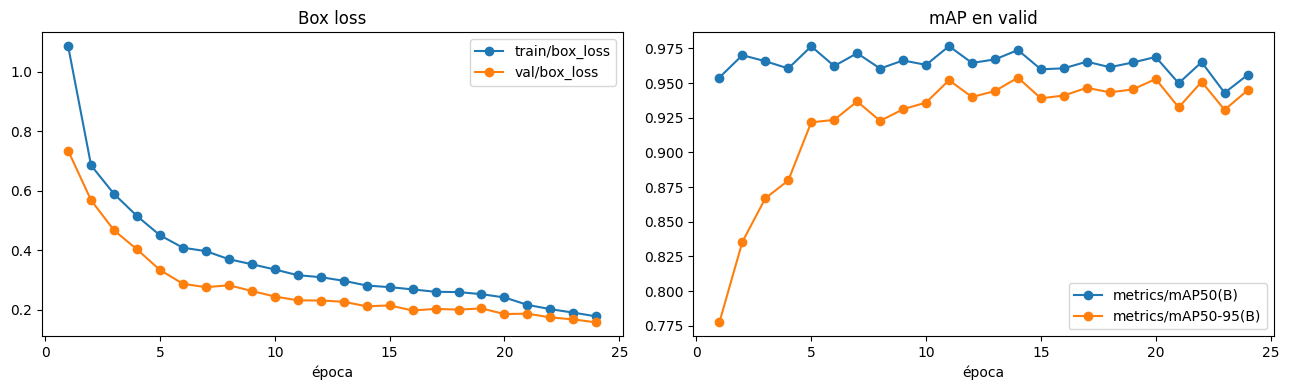

In [12]:
import matplotlib.pyplot as plt

rcsv = RUNS_DIR / RUN_NAME / "results.csv"
if rcsv.exists():
    r = pd.read_csv(rcsv)
    r.columns = [c.strip() for c in r.columns]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for c in ["train/box_loss", "val/box_loss"]:
        ax[0].plot(r["epoch"], r[c], marker="o", label=c)
    ax[0].set_title("Box loss"); ax[0].set_xlabel("época"); ax[0].legend()
    for c in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
        ax[1].plot(r["epoch"], r[c], marker="o", label=c)
    ax[1].set_title("mAP en valid"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout()
else:
    print("No encontré", rcsv)

### Interpretación de las curvas de entrenamiento

- **Pérdida de caja:** baja de forma sostenida en train (de 1,08 a 0,18) y en validación (de 0,73 a 0,16).
- **Validación por debajo de train:** la pérdida de validación se mantiene por debajo de la de train durante todo el entrenamiento. Es esperable, porque la pérdida de train se calcula con *data augmentation* y promediada a lo largo de la época.
- **Sin sobreajuste:** no aparece la divergencia típica (train bajando mientras valid sube).
- **mAP@0.5:** supera 0,95 desde la primera época y luego oscila entre 0,94 y 0,98. El modelo preentrenado resuelve casi de inmediato la tarea de detectar y clasificar cada plaza.
- **mAP@0.5:0.95:** es lo que más tarda en mejorar, porque mide la precisión de localización de las cajas. Pasa de 0,78 en la época 1 a 0,92 en la época 5, y alcanza su máximo (0,954) en la época 14. Después se estabiliza entre 0,93 y 0,95.
- **Elección del mejor checkpoint:** las diferencias dentro de esa meseta (entre 0,01 y 0,02) están dentro del ruido entre épocas, así que elegir la época 14 es poco más que una convención.
- **Early stopping:** detuvo el entrenamiento en la época 24 (patience = 10). La pérdida seguía bajando sin traducirse en mejoras de mAP, por lo que entrenar más épocas no aportaría.
- **Alcance de estas curvas:** corresponden al split de validación de `por_dia` (días no vistos de las mismas tres cámaras). No anticipan el desempeño en un estacionamiento nuevo.

## 6. Próximos pasos

Seguimos las líneas definidas al cierre del notebook 02. Marcadas, las que ya están cubiertas:

1. **Entrenar y comparar al menos dos arquitecturas**
   - [x] One-stage: YOLO11m (Ultralytics) con `STRATEGY = "por_dia"`, usado como baseline.
   - [ ] Repetir YOLO11m con `STRATEGY = "oficial"` (comparable con otros trabajos) y con `por_camara_*` (generalización a un estacionamiento nuevo).
   - [ ] Two-stage o transformer: Faster R-CNN (torchvision, usando `annotations_clean.coco.json`) o RT-DETR (`MODEL = "rtdetr-l.pt"`, misma librería), con la misma configuración de entrenamiento.
2. **Métricas** (precision, recall, F1, mAP@0.5 y mAP@0.5:0.95, global, por clase y por cámara, y tiempo de inferencia en ms/imagen y FPS en el mismo hardware)
   - [x] Calculadas para YOLO11m y guardadas en `metricas_yolo11m_por_dia.csv`.
   - [ ] Juntar las `metricas_*.csv` de Drive en una tabla comparativa única. Para P, R y F1 usar un umbral de confianza fijo e igual para todos los modelos.
3. **Post-proceso**
   - [ ] Calcular el % de ocupación por frame (ocupados / total detectado) y compararlo con el ground truth.
   - [ ] Definir la ROI de plazas anotadas, ya que solo un subconjunto de las plazas visibles tiene etiqueta (ver EDA).
4. **Demo**
   - [ ] Conseguir un video corto de un estacionamiento (vista elevada fija), inferir frame a frame y superponer el conteo de libres y ocupados.
   - [ ] Evaluar suavizado temporal (por ejemplo tracking) para estabilizar el conteo.